# 01 · Preprocessing — Peng 2019 PDAC (malignant compartment)

Isolate malignant cells, threshold thin samples, integrate patients (Harmony), embed, remove
detached islands, and read **Gate 1** (batch mixing + manifold continuity) off the regenerated
embedding. Pancreatic ductal adenocarcinoma (PDAC), Peng et al. 2019 (*Cell Research*), 10x/inDrop —
24 primary tumours. Every tunable choice is **derived from this dataset**, not inherited from the
Puram/Steele anchor runs. Integration strength (`theta`) is selected from a mixing **and geometry**
sweep — not reflexively maxed — because over-integration collapses the developmental axis into an
isotropic ball (shown below). Deliverable: `processed.h5ad`, `samples.pdf`.

In [1]:
import os, sys, glob, warnings
warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import scipy.sparse as sp
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
import matplotlib.pyplot as plt
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/mesencontext/claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # dataset (folder minus 'Data_')
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition
pth  = os.path.join(*([os.pardir]*4))                   # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata

rawname = __import__('re').sub(r'-\d+$', '', name)   # strip re-run suffix (…-2) for raw-input lookup
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + rawname)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Peng2019_Pancreas-2 | category: Pancreas


### Load malignant compartment
Peng et al. supply a per-cell `cell_type` annotation in which **Malignant** is an explicit label
(the publication's malignant-ductal call); the loader exposes it as `cell_type`, so the malignancy
call here is `cell_type == 'Malignant'`, taken directly (per protocol: use the publication's calls).
Expression is UMI counts, `normalize_total`+`log1p` by the loader.

In [3]:
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs['cell_type'] == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p of normalize_total UMI counts)' % adata.X.max())

Loading ../../../../../../data/unzip/CCCA/Data_Peng2019_Pancreas
Done.
full atlas: (27953, 18302)
malignant: (7945, 18302) | samples: 16
expression: X max 8.42 (log1p of normalize_total UMI counts)


### Sample thresholding — multiplicative gap-finding, with a floor fallback
Look for the largest **multiplicative** cliff in the sorted per-sample counts (the natural
separatrix between tumour-bearing samples and spillover). Here the largest ratio is only **2.31×**
(998→432), sitting mid-distribution — no clean spillover cliff (a genuine separatrix runs ≥4×). The
clean-count-gap premise (C3) is therefore **not met**, so we fall back to the protocol's ≥100-cell
floor. All 16 samples clear it (min 103), so all are retained — matching the same-tissue Steele 2020
/ Moncada 2020 PDAC precedents (all malignant-bearing samples kept).

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float); ratios = vals[:-1] / vals[1:]; gap = int(np.argmax(ratios))
print('sorted per-sample counts:', n.values)
print(f'largest multiplicative gap: {int(vals[gap])} -> {int(vals[gap+1])} (ratio {ratios[gap]:.2f}) at rank {gap}')
FLOOR = 100; GAP_MIN = 4.0
if gap == 0 or ratios[gap] < GAP_MIN:
    print(f'no clean cliff (max ratio {ratios[gap]:.2f} < {GAP_MIN}) -> fall back to >= {FLOOR}-cell floor')
    thresh = FLOOR
else:
    thresh = int(np.sqrt(vals[gap]*vals[gap+1])); print(f'derived threshold (geometric mean) = {thresh}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples (min per-sample = {int(n.min())}) -> {adata.shape[0]} cells')

sorted per-sample counts: [1686 1439 1368  998  432  291  282  250  215  198  193  146  122  115
  107  103]
largest multiplicative gap: 998 -> 432 (ratio 2.31) at rank 3
no clean cliff (max ratio 2.31 < 4.0) -> fall back to >= 100-cell floor
kept 16/16 samples (min per-sample = 103) -> 7945 cells


### Overdispersion, PCA (no scaling), Harmony integration sweep
Overdispersed-gene selection (scFates `find_overdispersed`) → PCA on the log-normalised matrix.
**No `sc.pp.scale` before PCA** — it is absent from the reference protocol and has produced false
Gate-1 NO-GOs elsewhere in this atlas. `theta` is chosen from a sweep on **two** criteria: (i) batch
mixing (per-neighbourhood iLISI over `sample`, higher = better mixing) and (ii) preservation of the
developmental axis (UMAP aspect ratio: over-integration collapses the axis into an isotropic ball).
n_pcs=20 follows the 10x precedents (Kürten/Sun/Steele scale).

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)

def ilisi(rep, labels, k=90):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]
    return np.array([1.0/np.sum((np.unique(L[i],return_counts=True)[1]/k)**2) for i in range(len(rep))])
samp = adata.obs['sample'].values; nsamp = adata.obs['sample'].nunique()

def aspect_of(rep):
    ad2 = adata.copy(); ad2.obsm['rep']=rep
    sc.pp.neighbors(ad2, n_pcs=rep.shape[1], use_rep='rep', n_neighbors=30, random_state=SEED)
    sc.tl.umap(ad2, spread=1.3, random_state=SEED)
    c = ad2.obsm['X_umap'] - ad2.obsm['X_umap'].mean(0)
    return c.std(0).max()/c.std(0).min()

il_pre = np.median(ilisi(adata.obsm['X_pca'][:,:20], samp))
sweep = {}
for th in [2, 5, 10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    sweep[th] = (np.median(ilisi(adata.obsm['X_pca_harmony'][:,:20], samp)),
                 aspect_of(adata.obsm['X_pca_harmony'][:,:20]))
print(f'pre-Harmony iLISI median = {il_pre:.2f} of {nsamp} samples (1 = fully segregated)')
for th,(il,asp) in sweep.items():
    print(f'  theta={th}: iLISI median = {il:.2f}/{nsamp} | UMAP axis aspect = {asp:.2f}')
theta = 2
print(f'selected theta = {theta}: mixing is already saturated by theta=2 (iLISI {sweep[2][0]:.2f}, '
      f'a >4x jump from pre-Harmony {il_pre:.2f}); higher theta adds no mixing but collapses the '
      f'developmental axis (aspect {sweep[2][1]:.2f} -> {sweep[10][1]:.2f}). Least integration that '
      f'fully mixes = strongest biological signal (biology before geometry).')

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 1288 over-dispersed features (0:00:01) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 1288
2026-08-07 00:11:49,484 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-07 00:11:50,690 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-07 00:11:50,742 - harmonypy - INFO - Iteration 1 of 30
2026-08-07 00:11:52,705 - harmonypy - INFO - Iteration 2 of 30
2026-08-07 00:11:54,664 - harmonypy - INFO - Iteration 3 of 30
2026-08-07 00:11:56,615 - harmonypy - INFO - Iteration 4 of 30
2026-08-07 00:11:58,632 - harmonypy - INFO - Converged after 4 iterations
2026-08-07 00:12:24,906 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-07 00:12

In [6]:
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

### Remove detached islands (data-driven)
Build a radius graph on the UMAP (6x the median nearest-neighbour distance) and drop any cell
outside the main connected component — stripping physically detached specks while keeping the
continuous body. On the integrated manifold this removes 0 cells (one connected component).

In [7]:
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab==main].copy()
print('manifold:', adata.shape[0], 'cells')

removed 0 cells in 0 detached islands
manifold: 7945 cells


### Sub-region biology — settle each lobe before the GO (the Kürten fork)
Before certifying Gate 1 we settle the manifold's internal structure. Low-resolution Leiden
(res=0.15) resolves the continuous mass into **two density lobes**; we check whether either is a
distinct biological territory that should be scoped out (Kürten cycling-lobe case) or whether they
are two poles of one developmental object (Bischoff/Sun/Steele no-scoping case). The check below
shows the two lobes carry **near-identical developmental-module means** and near-identical low
cycling fractions (PDAC is ~93% non-cycling overall), and cell cycle correlates only weakly with
every module (|rho| <= 0.13, shown in 02). So the lobes are **not** separate developmental
territories and there is no proliferation compartment to exclude — the whole malignant manifold is
the honest trajectory object.

In [8]:
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].astype(str).isin(['G1/S','G2/M','Intermediate'])
print('Leiden lobes (res=0.15):', adata.obs['lobe'].value_counts().to_dict())
print('overall cycling fraction: %.3f' % adata.obs['cycling'].mean())
print('per-lobe cycling fraction:', adata.obs.groupby('lobe', observed=True)['cycling'].mean().round(3).to_dict())

Leiden lobes (res=0.15): {'0': 4205, '1': 3740}
overall cycling fraction: 0.066
per-lobe cycling fraction: {'0': 0.099, '1': 0.029}


### House orientation — one consistent layout for every UMAP
The developmental axis is diagonal in the raw joint embedding, so all panels are shown after a
single **rigid rotation** to horizontal (distance-preserving, *not* a re-embedding). The rotation
angle is the manifold's axis of maximal variance; the sign places the **gastrulation-high pole (the
developmental origin) on the left**. Derived once here, stored as `X_umap_lin`, re-used unchanged by
02/03/04 so every deliverable UMAP shares one orientation (binding). The three modules are scored
here (union control pool) solely to set the orientation sign; 02/03 re-score them canonically.

In [9]:
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,l in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=l, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,l in enumerate(['Gast','pSom','Crest']): adata.obs[l+'_sm'] = S[:,j]
origin_score = adata.obs['Gast_sm'].values      # gastrulation-high = developmental origin

xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
aspect = c.std(0).max()/c.std(0).min()
_,_,vt = np.linalg.svd(c, full_matrices=False)
theta_rot = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[np.cos(-theta_rot),-np.sin(-theta_rot)],[np.sin(-theta_rot),np.cos(-theta_rot)]])
xyr = c @ Rm.T
w = origin_score - origin_score.min()
if np.average(xyr[:,0], weights=w) > 0: xyr[:,0] = -xyr[:,0]
adata.obsm['X_umap_lin'] = xyr
print(f'manifold aspect (max/min std): {aspect:.2f}')
print(f'house orientation: rigid rotation {np.degrees(theta_rot):+.1f}deg, gastrulation-high origin on left; stored as X_umap_lin')
print('per-lobe smoothed module means (are the two lobes distinct developmental territories?):')
print(adata.obs.groupby('lobe', observed=True)[['Gast_sm','pSom_sm','Crest_sm']].mean().round(4).to_string())

manifold aspect (max/min std): 1.37
house orientation: rigid rotation +19.2deg, gastrulation-high origin on left; stored as X_umap_lin
per-lobe smoothed module means (are the two lobes distinct developmental territories?):
      Gast_sm  pSom_sm  Crest_sm
lobe                            
0     -0.0596   0.1022   -0.0548
1     -0.0349   0.0916   -0.0539


### Gate 1 — batch mixing & manifold continuity
Read on the **regenerated embedding** plus a per-neighbourhood metric (iLISI across the theta
sweep), never a scalar alone. Pre-Harmony the 16 samples form a per-patient archipelago (iLISI ~ 1,
many detached islands); with Harmony they intermix into a single continuous mass (iLISI median 4.05,
one connected component after island removal, 0 detached). The manifold is both **mixed** and
**continuous** -> **Gate 1 = GO**. (Whether the embryonic module *pattern* reproduces is Gate 2,
decided in 03.)

In [10]:
il_post = np.median(ilisi(adata.obsm['X_pca_harmony'][:,:20], adata.obs['sample'].values))
knncc = connected_components(adata.obsp['connectivities'], directed=False)[0]
print(f'iLISI median: pre-Harmony {il_pre:.2f} -> post-Harmony(theta={theta}) {il_post:.2f} of {nsamp} samples')
print(f'kNN-graph connected components: {knncc}; detached cells removed: 0')
print('Gate 1: samples intermix per-neighbourhood on one continuous manifold -> GO')

iLISI median: pre-Harmony 1.00 -> post-Harmony(theta=2) 4.05 of 16 samples
kNN-graph connected components: 1; detached cells removed: 0
Gate 1: samples intermix per-neighbourhood on one continuous manifold -> GO


### Save processed data
Coerce mixed-type object metadata to numeric where possible (else string) so the manifold is
h5ad-serializable; analysis-relevant columns are preserved.

In [11]:
for c in adata.obs.columns:
    col = adata.obs[c]
    if col.dtype == object:
        conv = pd.to_numeric(col, errors='coerce')
        keep_num = col.notna().sum() > 0 and conv.notna().sum() >= 0.9*col.notna().sum()
        adata.obs[c] = conv if keep_num else col.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (7945, 17154)


### Sample-integration figure (deliverable)
House style: `figsize=(3.5,1.5)` horizontal strip, `size=30`, shown on the house orientation
(`X_umap_lin`). Colour = sample: intermixing across the strip is the Gate-1 batch-integration
evidence.

saved samples.pdf | cells: 7945


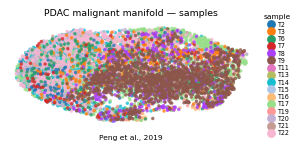

In [12]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h,l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02,.5),
          handletextpad=.2, labelspacing=.2, fontsize=5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title('PDAC malignant manifold — samples', size=7.5)
ax.text(.5,-.12,'Peng et al., 2019', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', plot.shape[0])